# BilanLab
### Du bilan financier à une extraction structurée et vérifiable

**Groupe 9 · Projet VLM · Soutenance et résultats mesurés · 15 novembre 2026**

Ce notebook présente le projet : le besoin, les choix de code, les méthodes comparées, les résultats et leurs limites. Chaque section comporte uniquement le code nécessaire à l'affichage ou à la vérification des résultats.

**Lecture directe :** les sorties sont déjà enregistrées. Pour les recalculer, exécuter les cellules dans l'ordre avec Python, pandas et IPython. Aucun appel API, téléchargement, accès au PDF original ou chargement de modèle n'est effectué. Les images masquées, graphiques, tableaux et réponses brutes sont intégrés à ce fichier.

Les grands tableaux sont complets et défilables ; les détails techniques se déplient. Le notebook technique `TP_Extraction_Bilans_VLM_Groupe9.ipynb` conserve l'implémentation complète des inférences.

In [1]:
import base64, hashlib, io, json, zlib
from collections import Counter
from decimal import Decimal
from html import escape
import pandas as pd
from IPython.display import HTML, Markdown, display

# Snapshot compressé des seules preuves de résultats ; aucun PDF original ni secret.
SNAPSHOT = '...'
raw = zlib.decompress(base64.b64decode(SNAPSHOT))
assert hashlib.sha256(raw).hexdigest() == 'acf9f6b48c0f2b5c450f49c98068a4eacca90ac7f73fc47d804247a1d0eeee4e'
D = json.loads(raw)

STYLE = """<style>
.bl{font:15px/1.65 -apple-system,BlinkMacSystemFont,'Segoe UI',sans-serif;color:#142838!important;background:#fff!important;color-scheme:light;max-width:1200px;padding:18px;box-sizing:border-box}
.bl h3{font-size:21px;color:#137d72;margin:18px 0 10px}.bl p{margin:10px 0}
.bl .kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(155px,1fr));gap:14px;margin:18px 0}
.bl .kpi{border-top:4px solid #137d72;background:#f1f7f7;padding:18px}.bl .value{display:block;font-size:29px;font-weight:700;line-height:1.3}
.bl .label{display:block;font-size:13px;color:#52697a;margin-top:8px}
.bl .note{background:#edf7f4;border-left:4px solid #137d72;padding:13px 18px;margin:16px 0}
.bl .warn{background:#fff6e7;border-color:#b77216;color:#704b17}
.bl .scroll{overflow:auto;max-height:530px;border:1px solid #dce6eb;margin:12px 0 22px}
.bl table{border-collapse:collapse;width:100%;font-size:13px;font-variant-numeric:tabular-nums}
.bl th{color:#142838!important;background:#eaf1f5!important;position:sticky;top:0;text-align:left;padding:10px;border-bottom:2px solid #d1dfe6}
.bl td{color:#142838!important;background:#fff!important;padding:9px 10px;border-bottom:1px solid #e2e9ed;vertical-align:top;min-width:85px}
.bl tbody tr:nth-child(even) td{background:#f7fafb!important}.bl img{display:block;max-width:100%;height:auto;margin:16px auto}
.bl details{margin:16px 0;border-top:1px solid #dce6eb;padding-top:12px}.bl summary{cursor:pointer;font-weight:600;color:#175b77}
.bl summary:focus-visible{outline:2px solid #137d72}.bl pre{color:#142838!important;white-space:pre;overflow:auto;max-height:520px;background:#f3f6f8!important;padding:16px;font-size:12px}
.bl .pages{display:flex;gap:16px;align-items:flex-start}.bl .pages img{width:48%}
</style>"""

def panel(content):
    display(HTML(STYLE + '<div class="bl" style="color:#142838;background-color:#ffffff;color-scheme:light">' + content + '</div>'))

def table(data, title, folded=False):
    frame = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
    content = '<h3>' + escape(title) + '</h3><p>' + str(len(frame)) + ' lignes — aucune troncature des données.</p>'
    content += '<div class="scroll">' + frame.to_html(index=False, na_rep='—', escape=True, max_rows=None, max_cols=None) + '</div>'
    panel('<details><summary>'+escape(title)+'</summary>'+content+'</details>' if folded else content)

def figure(name, caption):
    panel('<img alt="'+escape(caption, quote=True)+'" src="data:image/png;base64,'+D['figures'][name]+'"><p>'+escape(caption)+'</p>')

def details(title, value):
    text = json.dumps(value, ensure_ascii=False, indent=2) if not isinstance(value, str) else value
    panel('<details><summary>'+escape(title)+'</summary><pre>'+escape(text)+'</pre></details>')

CURRENT = pd.read_csv(io.StringIO(D['csv_current']))
ALL = pd.read_csv(io.StringIO(D['csv_all']))
BENCH = CURRENT[CURRENT.experience.str.startswith('ablation_validee_')].copy()
ROWS = [r for p in D['main']['pages'] for r in p['lignes']]
COLUMNS = ['montant_brut_N','montant_amort_N','montant_net_N','montant_net_N1']
assert len(ROWS)==88 and len(BENCH)==18 and len(D['local']['trials'])==3
print('Résultats intégrés chargés. Aucun appel à un modèle et aucun fichier externe nécessaire.')

Résultats intégrés chargés. Aucun appel à un modèle et aucun fichier externe nécessaire.


## 01 — Ce que le projet a obtenu

L'objectif est de transformer un bilan en données structurées puis de vérifier leur fidélité. Les indicateurs ci-dessous décrivent **le document fourni**, utilisé aussi au développement. Ils ne démontrent pas une fiabilité universelle.

In [2]:
metrics = [('2', 'pages de bilan'), ('88', 'postes normalisés'), ('107/107', 'montants API exacts'),
           ('66', 'contrôles numériques cohérents'), ('16,04 s', 'médiane locale hybride / 3 essais')]
panel('<div class="kpis">'+''.join('<div class="kpi"><span class="value">'+v+'</span><span class="label">'+t+'</span></div>' for v,t in metrics)+'</div>'
      +'<div class="note">La solution locale est une méthode hybride OCR + relecture Qwen. L’OCR seul est déjà exact sur ce bilan. L’ancien échec de Qwen seul est conservé.</div>')
table(D['local']['comparison'], 'Les quatre méthodes : exactitude et durée réelle')

methode,montants_exacts,duree_s,repetitions
Qwen seul / page entière,0,864.543255,1
OCR CPU seul,107,8.396715,1
OCR + Qwen ciblé,107,16.039804,3
API / livraison Python,107,31.694370,1


## 02 — Objectif du TP et travail réalisé

Le projet suit quatre responsabilités : comprendre le document, extraire, vérifier puis comparer. Les améliorations sont présentées comme des extensions du TP. Le fichier de l'énoncé s'appelle TP5, mais son titre intérieur indique TP3.

In [3]:
table([
 {'Partie':'A — Compréhension', 'Travail':'Lire actif/passif, années, signes, colonnes et pièges', 'Preuve':'Deux pages masquées et règles de représentation'},
 {'Partie':'B — Extraction API', 'Travail':'JSON minimal à quatre champs ; six stratégies de prompt', 'Preuve':'90 lignes minimales et 18 essais contrôlés'},
 {'Partie':'C — Local', 'Travail':'Ollama Qwen3-VL 4B Instruct sur CPU', 'Preuve':'Échec initial conservé, puis extension OCR + Qwen mesurée'},
 {'Partie':'D — Validation', 'Travail':'JSON, couverture, états, calculs et référence', 'Preuve':'88 postes, 352 cellules et 66 contrôles numériques'},
 {'Partie':'Extensions', 'Travail':'Scan dégradé, lot technique, interface web et soutenance', 'Preuve':'Journaux, figures, JSON et application'}
], 'Correspondance entre le besoin et les livrables')

Partie,Travail,Preuve
A — Compréhension,"Lire actif/passif, années, signes, colonnes et pièges",Deux pages masquées et règles de représentation
B — Extraction API,JSON minimal à quatre champs ; six stratégies de prompt,90 lignes minimales et 18 essais contrôlés
C — Local,Ollama Qwen3-VL 4B Instruct sur CPU,"Échec initial conservé, puis extension OCR + Qwen mesurée"
D — Validation,"JSON, couverture, états, calculs et référence","88 postes, 352 cellules et 66 contrôles numériques"
Extensions,"Scan dégradé, lot technique, interface web et soutenance","Journaux, figures, JSON et application"


## 03 — Lire le bilan et protéger son contenu

Les deux pages ci-dessous sont des **PNG masqués dans les pixels**. La clôture est au 31/12/2024. L'actif comporte brut, amortissement, net N et net N−1 ; le passif comporte uniquement les deux nets. L'unité n'est pas confirmée : aucune conversion en MAD n'est inventée. Le PDF original comportait une couche texte sous les masques visuels ; il n'est pas embarqué ici.


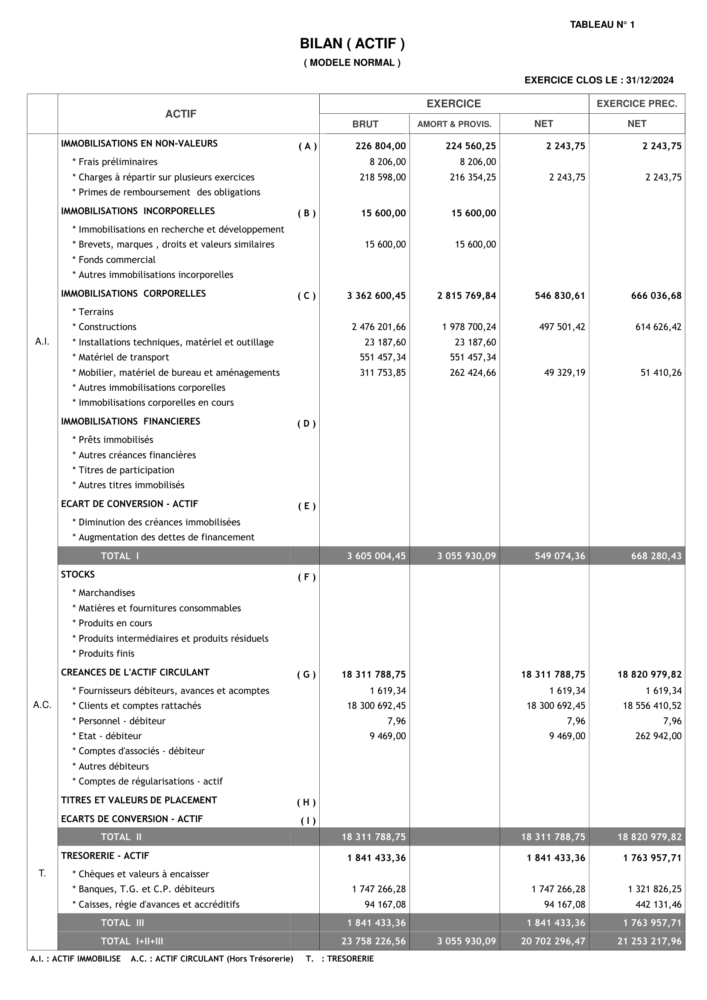
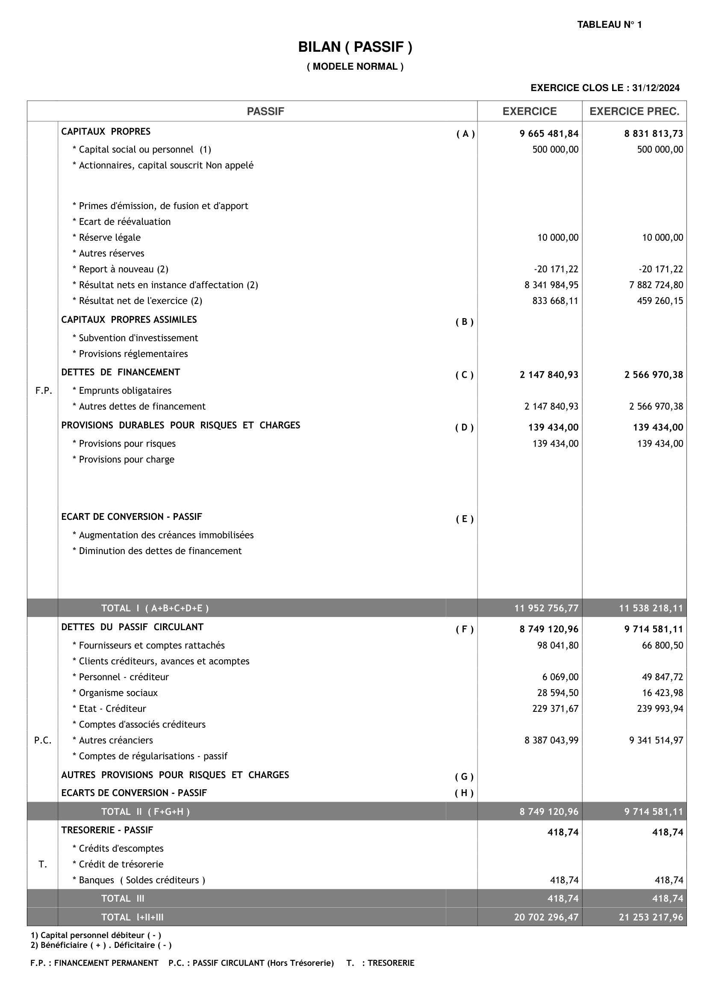

Piège,Réponse
Case vide ≠ zéro,Conserver null et un état explicite
Colonne absente du passif,"État non_applicable, distinct de vide"
Négatifs et espaces de milliers,"Chaînes décimales signées, puis Decimal"
Totaux et détails,Sommer uniquement les enfants directs
Mauvais masque PDF,Transmettre uniquement les PNG neufs contrôlés


In [4]:
panel('<div class="pages">'+''.join('<img alt="Page '+str(i)+' du bilan, identité masquée" src="data:image/png;base64,'+D['images']['page_'+str(i)]+'">' for i in (1,2))+'</div>')
table([
 {'Piège':'Case vide ≠ zéro', 'Réponse':'Conserver null et un état explicite'},
 {'Piège':'Colonne absente du passif', 'Réponse':'État non_applicable, distinct de vide'},
 {'Piège':'Négatifs et espaces de milliers', 'Réponse':'Chaînes décimales signées, puis Decimal'},
 {'Piège':'Totaux et détails', 'Réponse':'Sommer uniquement les enfants directs'},
 {'Piège':'Mauvais masque PDF', 'Réponse':'Transmettre uniquement les PNG neufs contrôlés'}
], 'Difficultés et solutions retenues')

## 04 — Architecture : où intervient chaque partie du code

`load_pdf` et `prepare_images` préparent les entrées. Les clients Gemini/Ollama réalisent l'inférence. `validate_page` filtre les objets, `arithmetic_checks` contrôle les calculs et `evaluate` compare aux annotations. Le catalogue contient seulement les libellés et la hiérarchie ; la référence chiffrée reste du côté évaluation. L'extension locale ajoute l'OCR et une relecture ciblée, présentés en section 11.


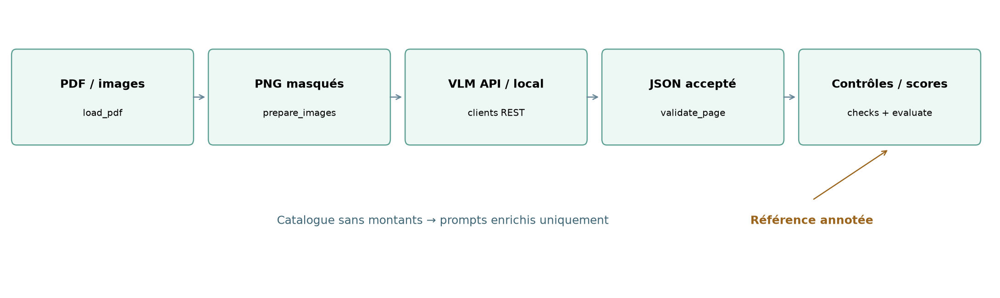

In [5]:
figure('00_architecture', 'Pipeline principal : préparation → modèle → contrat JSON → contrôles → évaluation.')

## 05 — Deux contrats JSON et quatre états de cellule

Le contrat minimal demandé contient **poste, rubrique, montant_net_N, montant_net_N1**. Le pipeline enrichi ajoute les identifiants, les parents, brut/amortissement et les états. Les 90 lignes imprimées deviennent 88 postes : le doublon Trésorerie / Total III est fusionné une fois par page, sans changer les montants.

État,Valeur
lu,"Chaîne décimale, y compris 0.00"
vide,null ; case blanche
illisible,null ; lecture incertaine
non_applicable,null ; colonne inexistante



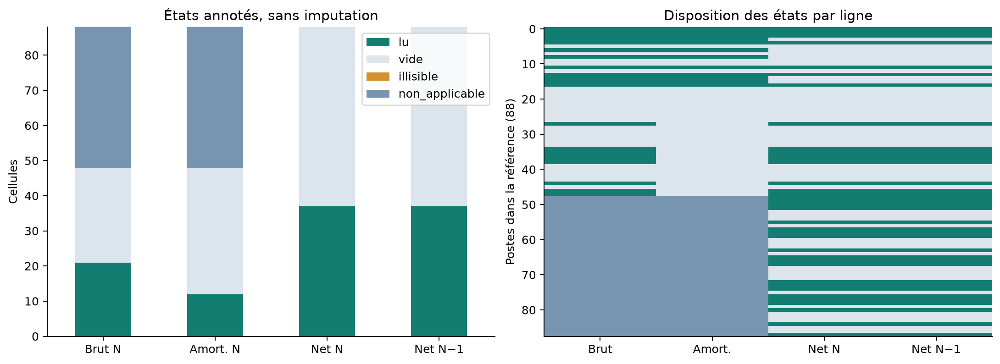

In [6]:
details('Exemple réel du JSON minimal — premières lignes', D['minimal']['pages'][0]['lignes'][:3])
table([{'État':'lu','Valeur':'Chaîne décimale, y compris 0.00'}, {'État':'vide','Valeur':'null ; case blanche'},
       {'État':'illisible','Valeur':'null ; lecture incertaine'}, {'État':'non_applicable','Valeur':'null ; colonne inexistante'}], 'Conventions de données')
figure('04_etats_et_couverture', 'Répartition des 352 états et couverture des postes.')
details('Catalogue complet sans montants', D['catalogue'])

## 06 — Comparer les prompts avec un protocole explicite

Six variantes cumulatives sont comparées, avec trois répétitions par variante : **18 essais** sur les mêmes images. Température 0, ordre mélangé avec graine 42, aucun réessai de validation dans le benchmark. Les répétitions ne sont pas des entreprises indépendantes. La livraison API relue est hors benchmark.

Variante,Ajout
baseline,"Consigne simple, sans rôle système"
role,Rôle de transcription comptable
constraints,Règles de lecture et de représentation
fewshot,"Exemple fictif, sans montant du bilan"
json_mode,Contrainte de sortie JSON
schema,Schéma de génération structuré



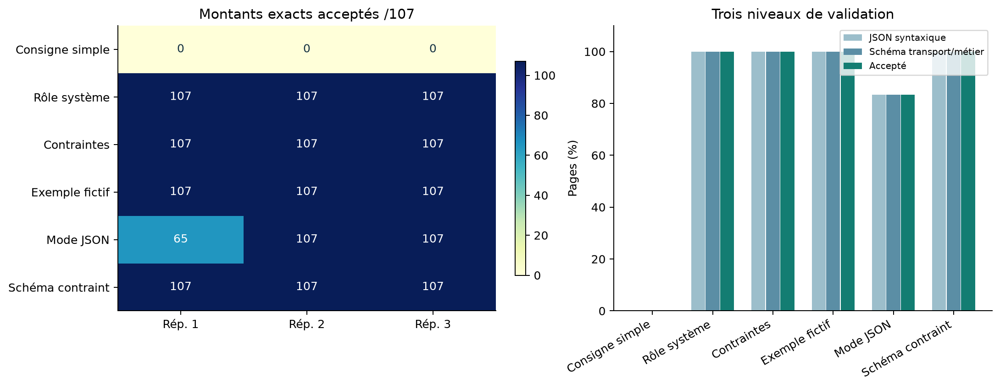

variante,experience,numeric_correct,numeric_total,taux_json,taux_schema,taux_acceptation,latence_document_s
baseline,ablation_validee_1,0.0,107.0,0.0,0.0,0.0,125.573614
baseline,ablation_validee_2,0.0,107.0,0.0,0.0,0.0,9.651130
baseline,ablation_validee_3,0.0,107.0,0.0,0.0,0.0,39.735481
constraints,ablation_validee_1,107.0,107.0,1.0,1.0,1.0,11.011733
constraints,ablation_validee_2,107.0,107.0,1.0,1.0,1.0,12.332585
constraints,ablation_validee_3,107.0,107.0,1.0,1.0,1.0,10.521716
fewshot,ablation_validee_1,107.0,107.0,1.0,1.0,1.0,31.287379
fewshot,ablation_validee_2,107.0,107.0,1.0,1.0,1.0,10.640317
fewshot,ablation_validee_3,107.0,107.0,1.0,1.0,1.0,27.672344
json_mode,ablation_validee_1,65.0,107.0,0.5,0.5,0.5,44.196854


In [7]:
table([
 {'Variante':'baseline', 'Ajout':'Consigne simple, sans rôle système'},
 {'Variante':'role', 'Ajout':'Rôle de transcription comptable'},
 {'Variante':'constraints', 'Ajout':'Règles de lecture et de représentation'},
 {'Variante':'fewshot', 'Ajout':'Exemple fictif, sans montant du bilan'},
 {'Variante':'json_mode', 'Ajout':'Contrainte de sortie JSON'},
 {'Variante':'schema', 'Ajout':'Schéma de génération structuré'}
], 'Les six stratégies et ce qui change')
figure('01_exactitude_et_validation', 'Exactitude et validation des 18 essais : les pages rejetées restent au dénominateur.')
table(BENCH[['variante','experience','numeric_correct','numeric_total','taux_json','taux_schema','taux_acceptation','latence_document_s']], 'Tous les essais du benchmark')
panel('<div class="note warn">Le score strict nul de la baseline est notamment lié au format Markdown rejeté. Il ne prouve pas que le modèle ne sait lire aucun chiffre. Le mode JSON a un essai à 65/107 après une page manquante lors d’un incident réseau.</div>')

## 07 — Vitesse et stabilité : regarder tous les essais

Les points individuels rendent les variations visibles. Une panne consomme aussi du temps. Les médianes sur trois répétitions décrivent cette session ; elles ne permettent pas de classer universellement les méthodes.


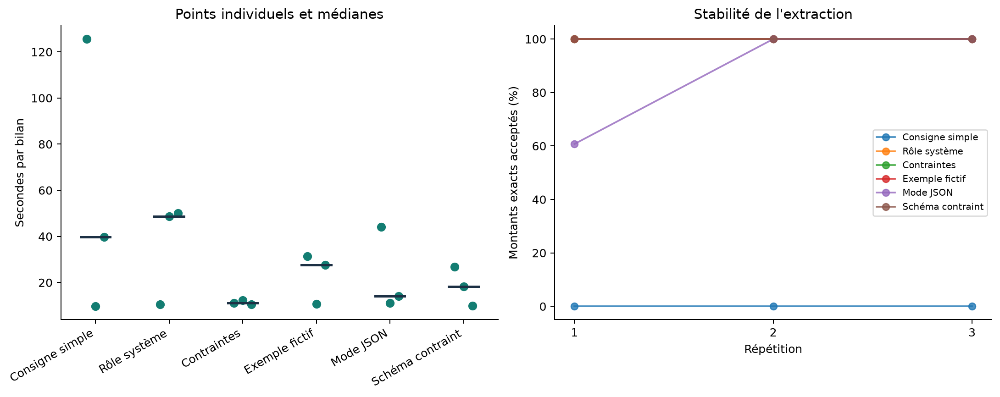

variante,count,mean,median,std,min,max
baseline,3,58.320075,39.735481,60.154351,9.651130,125.573614
constraints,3,11.288678,11.011733,0.936662,10.521716,12.332585
fewshot,3,23.200013,27.672344,11.026178,10.640317,31.287379
json_mode,3,23.124189,14.064812,18.309131,11.110902,44.196854
role,3,36.462541,48.732249,22.414565,10.591846,50.063529
schema,3,18.323017,18.303516,8.482925,9.849859,26.815676



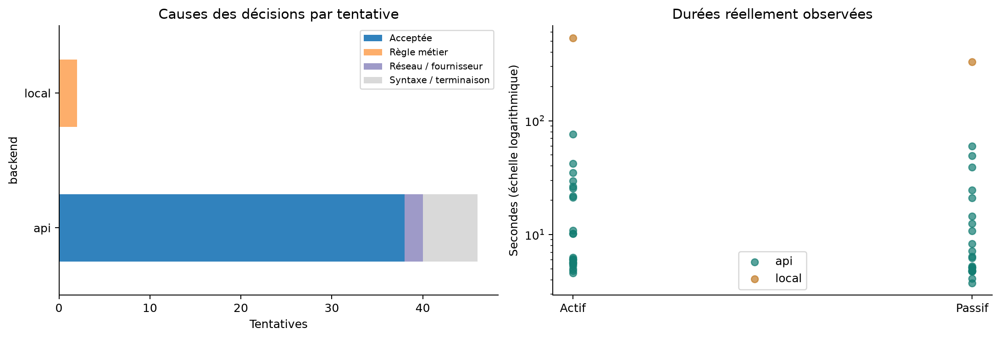

In [8]:
figure('02_latence_et_stabilite', 'Durées individuelles, médianes et stabilité des stratégies.')
table(BENCH.groupby('variante', sort=False).latence_document_s.agg(['count','mean','median','std','min','max']).reset_index(), 'Statistiques de durée, en secondes')
figure('03_pages_et_echecs', 'Détail des pages et causes de rejet : distinguer transport, syntaxe et validation.')

## 08 — Résultat API : toutes les lignes du bilan

L'extraction de livraison `principal_relecture` obtient 107/107 montants et 74/74 nets exacts, avec 88 postes, en 31,69 s. Elle est séparée de l'incident initial et des 18 essais. Les deux tableaux contiennent **toutes les lignes**, avec leurs valeurs imprimées ; les états détaillés sont disponibles juste après.

In [9]:
for nature in ['actif','passif']:
    subset = [r for r in ROWS if r['rubrique']==nature]
    table(pd.DataFrame(subset)[['id','parent_id','poste','type_ligne']+COLUMNS], 'Tous les postes — '+nature)
states = [{'id':r['id'],'poste':r['poste'],'colonne':c,'valeur':r[c],'etat':r['etats'][c]} for r in ROWS for c in COLUMNS]
table(states, 'Les 352 cellules : valeur et état', folded=True)
details('JSON API complet', D['main'])

id,parent_id,poste,type_ligne,montant_brut_N,montant_amort_N,montant_net_N,montant_net_N1
A_TOTAL,—,TOTAL I+II+III,total,23758226.56,3055930.09,20702296.47,21253217.96
A_I,A_TOTAL,TOTAL I actif immobilisé,sous_total,3605004.45,3055930.09,549074.36,668280.43
A_A,A_I,Immobilisations en non-valeurs,sous_total,226804.00,224560.25,2243.75,2243.75
A_A1,A_A,Frais préliminaires,detail,8206.00,8206.00,—,—
A_A2,A_A,Charges à répartir sur plusieurs exercices,detail,218598.00,216354.25,2243.75,2243.75
A_A3,A_A,Primes de remboursement des obligations,detail,—,—,—,—
A_B,A_I,Immobilisations incorporelles,sous_total,15600.00,15600.00,—,—
A_B1,A_B,Immobilisations en recherche et développement,detail,—,—,—,—
A_B2,A_B,"Brevets, marques, droits et valeurs similaires",detail,15600.00,15600.00,—,—
A_B3,A_B,Fonds commercial,detail,—,—,—,—


id,parent_id,poste,type_ligne,montant_brut_N,montant_amort_N,montant_net_N,montant_net_N1
P_TOTAL,—,TOTAL I+II+III,total,None,None,20702296.47,21253217.96
P_I,P_TOTAL,TOTAL I financement permanent,sous_total,None,None,11952756.77,11538218.11
P_A,P_I,Capitaux propres,sous_total,None,None,9665481.84,8831813.73
P_A1,P_A,Capital social ou personnel,detail,None,None,500000.00,500000.00
P_A2,P_A,"Actionnaires, capital souscrit non appelé",detail,None,None,—,—
P_A3,P_A,"Primes d'émission, de fusion et d'apport",detail,None,None,—,—
P_A4,P_A,Écart de réévaluation,detail,None,None,—,—
P_A5,P_A,Réserve légale,detail,None,None,10000.00,10000.00
P_A6,P_A,Autres réserves,detail,None,None,—,—
P_A7,P_A,Report à nouveau,detail,None,None,-20171.22,-20171.22


id,poste,colonne,valeur,etat
A_TOTAL,TOTAL I+II+III,montant_brut_N,23758226.56,lu
A_TOTAL,TOTAL I+II+III,montant_amort_N,3055930.09,lu
A_TOTAL,TOTAL I+II+III,montant_net_N,20702296.47,lu
A_TOTAL,TOTAL I+II+III,montant_net_N1,21253217.96,lu
A_I,TOTAL I actif immobilisé,montant_brut_N,3605004.45,lu
A_I,TOTAL I actif immobilisé,montant_amort_N,3055930.09,lu
A_I,TOTAL I actif immobilisé,montant_net_N,549074.36,lu
A_I,TOTAL I actif immobilisé,montant_net_N1,668280.43,lu
A_A,Immobilisations en non-valeurs,montant_brut_N,226804.00,lu
A_A,Immobilisations en non-valeurs,montant_amort_N,224560.25,lu


## 09 — Contrôles comptables et vérification exacte

Les contrôles vérifient les sommes des enfants directs, brut − amortissement = net et actif = passif. Ils utilisent Decimal avec une tolérance d'un centime. L'évaluation des montants contre la référence utilise une **égalité exacte**, sans tolérance. Une égalité comptable peut cacher deux erreurs compensées : elle ne remplace pas l'annotation.

montants_exacts,montants_attendus,cellules_exactes,cellules_attendues,postes
107,107,352,352,88



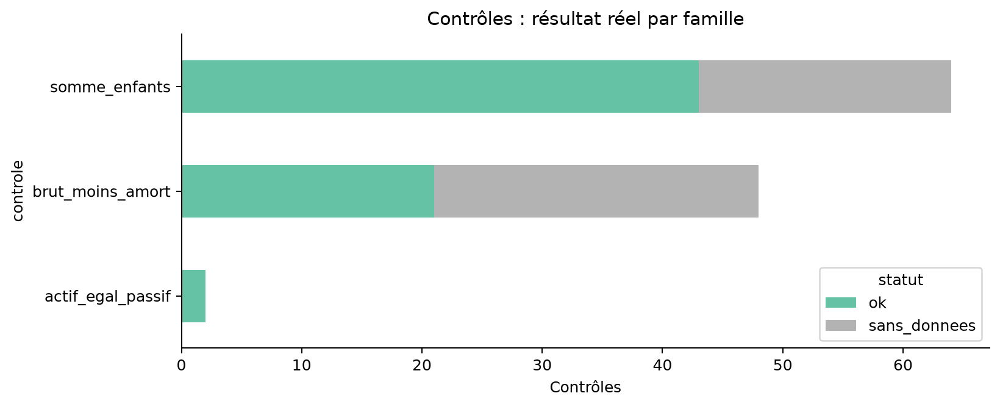

controle,id,colonne,statut,ecart
somme_enfants,A_TOTAL,montant_brut_N,ok,0.00
somme_enfants,A_TOTAL,montant_amort_N,ok,0.00
somme_enfants,A_TOTAL,montant_net_N,ok,0.00
somme_enfants,A_TOTAL,montant_net_N1,ok,0.00
brut_moins_amort,A_TOTAL,montant_net_N,ok,0.00
somme_enfants,A_I,montant_brut_N,ok,0.00
somme_enfants,A_I,montant_amort_N,ok,0.00
somme_enfants,A_I,montant_net_N,ok,0.00
somme_enfants,A_I,montant_net_N1,ok,0.00
brut_moins_amort,A_I,montant_net_N,ok,0.00


In [10]:
gold = {r['id']:r for r in D['reference']['lignes']}
def exact_result(result):
    predicted = {r['id']:r for p in result['pages'] for r in p['lignes']}
    correct = total = cells = 0
    for identifier, expected in gold.items():
        actual = predicted.get(identifier)
        for column in COLUMNS:
            value = expected[column]
            same = actual is not None and actual[column] is not None and value is not None and Decimal(actual[column])==Decimal(value)
            if value is not None:
                total += 1; correct += bool(same)
            cells += bool(actual is not None and actual['etats'][column]==expected['etats'][column]
                          and (same if value is not None else actual[column] is None))
    return {'montants_exacts':correct,'montants_attendus':total,'cellules_exactes':cells,'cellules_attendues':352,'postes':len(predicted)}

verification = exact_result(D['main'])
assert verification['montants_exacts']==107 and verification['cellules_exactes']==352
table([verification], 'Vérification recalculée à partir du JSON intégré')
figure('05_controles_comptables', '66 contrôles numériques cohérents ; les contrôles sans données restent distingués.')
table(D['checks'], 'Tous les contrôles comptables et leurs écarts')

## 10 — Comprendre l’échec initial de Qwen seul

Qwen3-VL 4B Instruct, quantifié Q4_K_M, a été exécuté sur CPU avec images plafonnées à 1400 pixels. La lecture brute retrouve 34/107 montants, mais les pages sont rejetées : 210 marqueurs NA dans des colonnes applicables et une année 3112. La durée est 864,54 s. Ce résultat concerne un modèle dense, sans exécution GPU/MoE.


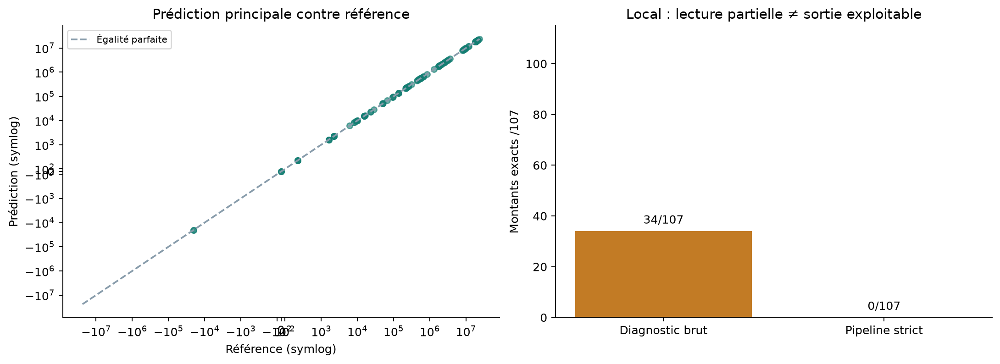

id,colonne,attendu,brut_modele
A_B2,montant_brut_N,15600.00,NA
A_B2,montant_amort_N,15600.00,NA
A_C,montant_brut_N,3362600.45,336200.45
A_C2,montant_brut_N,2476201.66,23187.60
A_C2,montant_amort_N,1978700.24,23187.60
A_C2,montant_net_N,497501.42,NA
A_C2,montant_net_N1,614626.42,NA
A_C3,montant_brut_N,23187.60,551457.34
A_C3,montant_amort_N,23187.60,551457.34
A_C4,montant_brut_N,551457.34,311753.85


In [11]:
figure('06_concordance_et_local', 'Concordance API et diagnostic local avant rejet : ne pas confondre les deux niveaux.')
table(D['diagnostic']['erreurs'], 'Tous les écarts numériques bruts de Qwen seul')
details('Diagnostic brut complet', D['diagnostic'])
details('Pilotes recadrés : réponses réellement obtenues', D['pilots'])
panel('<div class="note warn">Les pilotes de quatre lignes réduisent la génération mais inventent encore deux cases remplies. Une correction du JSON ne résout pas à elle seule la lecture des pixels.</div>')

## 11 — La solution locale retenue : OCR et relecture ciblée

RapidOCR lit les textes, positions et confiances. Le code associe les montants aux cellules par géométrie et par libellés du catalogue. Qwen relit ensuite les **quatre cellules de plus faible confiance**, avec leurs images et les propositions OCR. Un désaccord est marqué illisible. Aucun montant de référence ni calcul d'équilibrage n'est utilisé pour corriger la sortie. **L'OCR seul était déjà exact ici** : aucun gain causal de précision de Qwen n'est démontré.


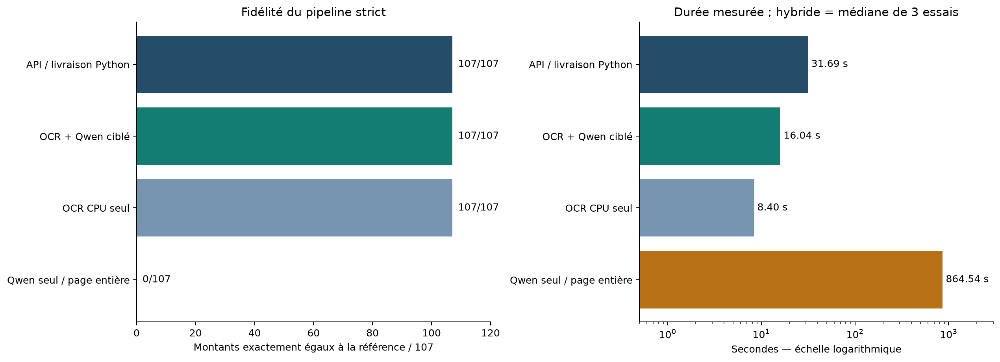

essai,archive,duree_s,ocr_s,qwen_s,accords_qwen,numeric_correct,numeric_total,exactitude_numerique,net_correct,net_total,exactitude_nette,exactitude_etats_valeurs,lignes_presentes,lignes_attendues,completude_lignes,controles_ok,ecarts,erreurs_cellules
1,hybride_essai_1.json,18.094435,7.633504,10.374851,4,107,107,1.0,74,74,1.0,1.0,88,88,1.0,66,0,0
2,hybride_1794750247285378900.json,16.039804,7.523498,8.452812,4,107,107,1.0,74,74,1.0,1.0,88,88,1.0,66,0,0
3,hybride_1794750263139258700.json,15.805513,7.008683,8.745868,4,107,107,1.0,74,74,1.0,1.0,88,88,1.0,66,0,0


montants_exacts,montants_attendus,cellules_exactes,cellules_attendues,postes
107,107,352,352,88


page,id,column,score,value,qwen,accord
1,A_T3,2,0.93405,94167.08,94167.08,True
1,A_G2,2,0.93565,18300692.45,18300692.45,True
1,A_I,1,0.93771,3055930.09,3055930.09,True
2,P_A8,3,0.94624,7882724.80,7882724.80,True


In [12]:
figure('12_optimisation_locale', 'Comparer les pipelines : OCR seul, OCR + Qwen, Qwen seul et API.')
table(D['local']['trials'], 'Les trois essais hybrides complets, sans sélectionner le meilleur')
assert exact_result(D['hybrid'])['montants_exacts']==107
assert exact_result(D['hybrid'])['cellules_exactes']==352
table([exact_result(D['hybrid'])], 'Vérification recalculée du JSON local hybride')
reviews = D['hybrid_raw']['review']['reviews']
table([{k:r[k] for k in ['page','id','column','score','value','qwen','accord']} for r in reviews], 'Les quatre cellules relues et les décisions de Qwen')
details('Réponse brute de la relecture Qwen', D['hybrid_raw']['review']['raw'])
panel('<div class="note warn">Trois essais sur un seul bilan ; Qwen était déjà chargé. Les coordonnées de colonnes sont adaptées au modèle normal fourni. Le rapport de durée avec l’ancien essai n’est pas un benchmark matériel apparié à froid.</div>')

## 12 — Toutes les preuves de l’extraction locale

Les tableaux suivants permettent de contrôler les détections, les lignes finales et les calculs. Une confiance OCR n'est pas une probabilité garantie d'exactitude. Une absence de détection peut devenir une fausse case vide sur un document inconnu ; il faut donc valider d'autres mises en page.

In [13]:
table([r for p in D['hybrid']['pages'] for r in p['lignes']], 'Les 88 postes locaux, avec leurs états', folded=True)
table(D['hybrid_checks'], 'Tous les contrôles du résultat hybride', folded=True)
table([{**r,'page':i} for i,rows in enumerate(D['hybrid_raw']['detections'],1) for r in rows], 'Toutes les détections OCR : texte, position et score', folded=True)
table(D['hybrid_raw']['evidence'], 'Tous les montants OCR alignés aux cellules', folded=True)
details('JSON local hybride complet', D['hybrid'])

id,parent_id,poste,rubrique,type_ligne,etats,montant_brut_N,montant_amort_N,montant_net_N,montant_net_N1
A_TOTAL,—,TOTAL I+II+III,actif,total,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'lu', 'montant_net_N1': 'lu'}",23758226.56,3055930.09,20702296.47,21253217.96
A_I,A_TOTAL,TOTAL I actif immobilisé,actif,sous_total,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'lu', 'montant_net_N1': 'lu'}",3605004.45,3055930.09,549074.36,668280.43
A_A,A_I,Immobilisations en non-valeurs,actif,sous_total,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'lu', 'montant_net_N1': 'lu'}",226804.00,224560.25,2243.75,2243.75
A_A1,A_A,Frais préliminaires,actif,detail,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'vide', 'montant_net_N1': 'vide'}",8206.00,8206.00,—,—
A_A2,A_A,Charges à répartir sur plusieurs exercices,actif,detail,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'lu', 'montant_net_N1': 'lu'}",218598.00,216354.25,2243.75,2243.75
A_A3,A_A,Primes de remboursement des obligations,actif,detail,"{'montant_brut_N': 'vide', 'montant_amort_N': 'vide', 'montant_net_N': 'vide', 'montant_net_N1': 'vide'}",—,—,—,—
A_B,A_I,Immobilisations incorporelles,actif,sous_total,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'vide', 'montant_net_N1': 'vide'}",15600.00,15600.00,—,—
A_B1,A_B,Immobilisations en recherche et développement,actif,detail,"{'montant_brut_N': 'vide', 'montant_amort_N': 'vide', 'montant_net_N': 'vide', 'montant_net_N1': 'vide'}",—,—,—,—
A_B2,A_B,"Brevets, marques, droits et valeurs similaires",actif,detail,"{'montant_brut_N': 'lu', 'montant_amort_N': 'lu', 'montant_net_N': 'vide', 'montant_net_N1': 'vide'}",15600.00,15600.00,—,—
A_B3,A_B,Fonds commercial,actif,detail,"{'montant_brut_N': 'vide', 'montant_amort_N': 'vide', 'montant_net_N': 'vide', 'montant_net_N1': 'vide'}",—,—,—,—


controle,id,colonne,statut,ecart
somme_enfants,A_TOTAL,montant_brut_N,ok,0.00
somme_enfants,A_TOTAL,montant_amort_N,ok,0.00
somme_enfants,A_TOTAL,montant_net_N,ok,0.00
somme_enfants,A_TOTAL,montant_net_N1,ok,0.00
brut_moins_amort,A_TOTAL,montant_net_N,ok,0.00
somme_enfants,A_I,montant_brut_N,ok,0.00
somme_enfants,A_I,montant_amort_N,ok,0.00
somme_enfants,A_I,montant_net_N,ok,0.00
somme_enfants,A_I,montant_net_N1,ok,0.00
brut_moins_amort,A_I,montant_net_N,ok,0.00


box,text,score,page
"[[1329.77832, 42.441532], [1489.539673, 42.441532], [1489.539673, 69.556953], [1329.77832, 69.556953]]",TABLEAU N° 1,0.97707,1
"[[697.78125, 82.5252], [951.519836, 82.5252], [951.519836, 121.429939], [697.78125, 121.429939]]",BILAN(ACTIF),0.99845,1
"[[706.004211, 130.861389], [942.122131, 130.861389], [942.122131, 161.513611], [706.004211, 161.513611]]",(MODELE NORMAL),0.99961,1
"[[1221.704468, 170.945068], [1579.992798, 173.302933], [1579.992798, 200.41835], [1221.704468, 198.060486]]",EXERCICE CLOS LE : 31/12/2024,0.99234,1
"[[992.634888, 222.818054], [1130.07666, 225.175919], [1130.07666, 257.00705], [992.634888, 254.6492]]",EXERCICE,0.99992,1
"[[1392.03833, 227.533768], [1587.041138, 227.533768], [1587.041138, 254.6492], [1392.03833, 254.6492]]",EXERCICE PREC.,0.99973,1
"[[380.607941, 248.754547], [465.1875, 248.754547], [465.1875, 281.764618], [380.607941, 281.764618]]",ACTIF,0.99985,1
"[[818.776978, 274.69104], [891.609375, 274.69104], [891.609375, 304.164307], [818.776978, 304.164307]]",BRUT,0.99996,1
"[[972.664734, 275.869965], [1153.571045, 275.869965], [1153.571045, 302.985382], [972.664734, 302.985382]]",AMORT & PROVIS.,0.99936,1
"[[1241.674683, 271.154236], [1302.759888, 271.154236], [1302.759888, 305.343262], [1241.674683, 305.343262]]",NET,0.99993,1


box,text,score,x,y,id,column,value,page
"[[827.0, 326.564026], [953.869263, 326.564026], [953.869263, 354.858368], [827.0, 354.858368]]","226 804,00",0.95165,0.538352,0.145665,A_A,0,226804.00,1
"[[1036.099365, 323.027222], [1165.318115, 325.385101], [1165.318115, 357.216248], [1036.099365, 354.858368]]","224 560,25",0.99974,0.665483,0.145413,A_A,1,224560.25,1
"[[1271.042603, 325.385101], [1374.417603, 325.385101], [1374.417603, 357.216248], [1271.042603, 357.216248]]","2 243,75",0.96758,0.799716,0.145917,A_A,2,2243.75,1
"[[1497.762695, 326.564026], [1598.78833, 326.564026], [1598.78833, 354.858368], [1497.762695, 354.858368]]","2 243,75",0.97831,0.936080,0.145665,A_A,3,2243.75,1
"[[858.717285, 361.931976], [956.21875, 361.931976], [956.21875, 393.763123], [858.717285, 393.763123]]","8 206,00",0.97155,0.548651,0.161542,A_A1,0,8206.00,1
"[[1068.991455, 361.931976], [1166.49292, 361.931976], [1166.49292, 393.763123], [1068.991455, 393.763123]]","8 206,00",0.96368,0.675781,0.161542,A_A1,1,8206.00,1
"[[835.222961, 398.478851], [955.044006, 398.478851], [955.044006, 430.309998], [835.222961, 430.309998]]","218 598,00",0.99588,0.541193,0.177167,A_A2,0,218598.00,1
"[[1047.846558, 399.657776], [1164.143433, 399.657776], [1164.143433, 427.952118], [1047.846558, 427.952118]]","216354,25",0.99998,0.668679,0.176915,A_A2,1,216354.25,1
"[[1278.09082, 396.120972], [1375.592285, 398.478851], [1374.417603, 431.488922], [1276.916138, 429.131042]]","2 243,75",0.99202,0.801847,0.176915,A_A2,2,2243.75,1
"[[1503.636353, 396.120972], [1601.137695, 398.478851], [1599.963013, 431.488922], [1502.461548, 429.131042]]","2 243,75",0.98997,0.938210,0.176915,A_A2,3,2243.75,1


## 13 — Exploiter les montants extraits

Le total actif/passif N vaut 20 702 296,47, contre 21 253 217,96 en N−1, soit environ −2,59 %. Les créances clients représentent environ 88,40 % de l'actif N. Il s'agit d'une description du document, sans inventer d'unité ni produire de recommandation financière.


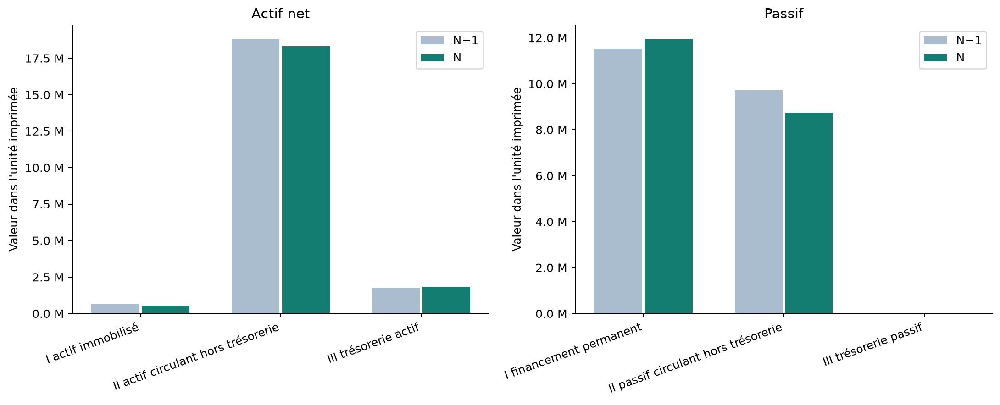

id,poste,montant_net_N,montant_net_N1
A_TOTAL,TOTAL I+II+III,20702296.47,21253217.96
A_I,TOTAL I actif immobilisé,549074.36,668280.43
A_A,Immobilisations en non-valeurs,2243.75,2243.75
A_B,Immobilisations incorporelles,—,—
A_C,Immobilisations corporelles,546830.61,666036.68
A_D,Immobilisations financières,—,—
A_E,Écart de conversion actif immobilisé,—,—
A_II,TOTAL II actif circulant hors trésorerie,18311788.75,18820979.82
A_F,Stocks,—,—
A_G,Créances de l'actif circulant,18311788.75,18820979.82


In [14]:
figure('07_structure_bilan', 'Composition du bilan et évolution entre N et N−1, dans l’unité imprimée.')
by_id = {r['id']:r for r in ROWS}
table([{k:r[k] for k in ['id','poste','montant_net_N','montant_net_N1']} for r in ROWS if r['type_ligne'] in ['total','sous_total']], 'Tous les totaux et sous-totaux des deux exercices')

## 14 — Robustesse, lot et version minimale du TP

Le scan synthétique réduit, flouté et moins contrasté reste exact dans l'essai API à 65,88 s. Le lot contient deux fichiers du même bilan : original et scan dérivé. Il ne constitue pas deux entreprises. La version minimale à quatre champs conserve les 90 lignes imprimées avant normalisation.


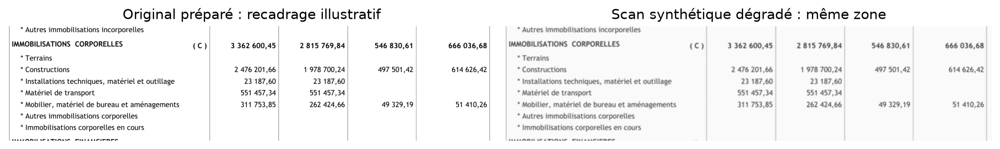

backend,modele,variante,experience,document_complet,numeric_correct,numeric_total,exactitude_numerique,net_correct,net_total,exactitude_nette,exactitude_etats_valeurs,lignes_presentes,lignes_attendues,completude_lignes,latence_s,controles_ok,controles_ecart,controles_indetermines,erreurs,run_dir
api,gemini-3.1-flash-lite,schema,scan_degrade_valide,True,107,107,1.0,74,74,1.0,1.0,88,88,1.0,65.884587,66,0,0,{},[projet]\outputs_vlm\runs\bilan_group_9_api_schema_scan_degrade_valide_20261115T084551Z_7f4a40


fichier,complet,run_dir
bilan_group_9.pdf,True,[projet]\outputs_vlm\runs\bilan_group_9_api_schema_batch_valide_20261115T084658Z_3fdb16
bilan_group9_scan_synthetique.pdf,True,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261115T084714Z_8da98e


page,poste,rubrique,montant_net_N,montant_net_N1
1,IMMOBILISATIONS EN NON-VALEURS,actif,2243.75,2243.75
1,Frais préliminaires,actif,—,—
1,Charges à répartir sur plusieurs exercices,actif,2243.75,2243.75
1,Primes de remboursement des obligations,actif,—,—
1,IMMOBILISATIONS INCORPORELLES,actif,—,—
1,Immobilisations en recherche et développement,actif,—,—
1,"Brevets, marques, droits et valeurs similaires",actif,—,—
1,Fonds commercial,actif,—,—
1,Autres immobilisations incorporelles,actif,—,—
1,IMMOBILISATIONS CORPORELLES,actif,546830.61,666036.68


In [15]:
figure('09_scan_original_et_degrade', 'Même zone : original et dégradation synthétique.')
table([r for r in D['summary'] if r['experience'] in ['scan_degrade_valide','batch_valide']], 'Résultats des tests de robustesse et du lot')
table(D['batch'], 'Les deux entrées du lot technique')
table([{'page':p['page'],**r} for p in D['minimal']['pages'] for r in p['lignes']], 'Les 90 lignes du JSON minimal réellement extrait', folded=True)

## 15 — Tokens, coût et limites de la comparaison

L'estimation API utilise les compteurs connus et les tarifs documentés au 15/11/2026 : 0,25 USD par million de tokens d'entrée et 1,50 USD en sortie. Une donnée de coût inconnue reste absente, pas zéro. La livraison compte 5 935 tokens d'entrée et 3 359 de sortie, soit environ 0,00652 USD à ce tarif. Ce n'est pas une facture ; le coût matériel et électrique local n'est pas mesuré.


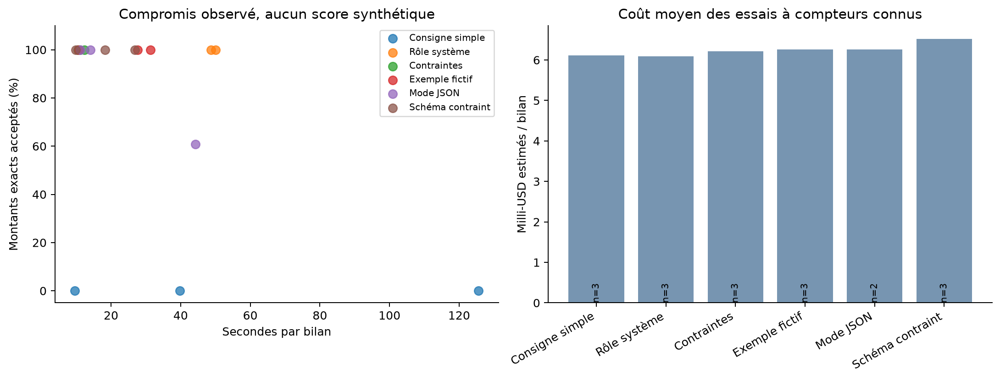

backend,variante,experience,tokens_entree_connus,tokens_sortie_connus,cout_api_estime_usd,latence_document_s,numeric_correct
api,baseline,ablation_validee_1,5175.0,3211.0,0.006110,125.573614,0.0
api,baseline,ablation_validee_2,5175.0,3211.0,0.006110,9.651130,0.0
api,baseline,ablation_validee_3,5175.0,3211.0,0.006110,39.735481,0.0
api,constraints,ablation_validee_1,5755.0,3183.0,0.006213,11.011733,107.0
api,constraints,ablation_validee_2,5755.0,3183.0,0.006213,12.332585,107.0
api,constraints,ablation_validee_3,5755.0,3183.0,0.006213,10.521716,107.0
api,fewshot,ablation_validee_1,5935.0,3183.0,0.006258,31.287379,107.0
api,fewshot,ablation_validee_2,5935.0,3183.0,0.006258,10.640317,107.0
api,fewshot,ablation_validee_3,5935.0,3183.0,0.006258,27.672344,107.0
api,json_mode,ablation_validee_1,—,—,—,44.196854,65.0


In [16]:
figure('08_cout_et_compromis', 'Compromis mesuré entre durée, exactitude et coût estimable.')
table(CURRENT[['backend','variante','experience','tokens_entree_connus','tokens_sortie_connus','cout_api_estime_usd','latence_document_s','numeric_correct']], 'Tous les compteurs et coûts estimables de la campagne')

## 16 — Journaux et résultats complets, y compris les échecs

Cette section conserve toutes les expériences archivées, puis tous les journaux et réponses brutes. La campagne actuelle et les essais historiques sont distingués. Les archives ne sont pas de nouveaux documents indépendants ; un essai rejeté n'est pas remplacé par une sortie réparée à partir du gold.

In [17]:
table(CURRENT, 'Toutes les mesures de la campagne actuelle', folded=True)
table(ALL, 'Toutes les mesures historiques disponibles', folded=True)
attempts = [{'dossier':r['dossier'],'experience':r['bilan'].get('label'),**log} for r in D['runs'] for log in r['journal']]
table(attempts, 'Tous les journaux de tentatives de pages', folded=True)
body = ''
for run in D['runs']:
    title = run['bilan'].get('backend','')+' / '+run['bilan'].get('label','')+' / '+run['dossier']
    body += '<details><summary>'+escape(title)+'</summary><pre>'+escape(json.dumps(run,ensure_ascii=False,indent=2))+'</pre></details>'
panel('<details><summary>Archives complètes : '+str(len(D['runs']))+' expériences, JSON et réponses brutes</summary>'+body+'</details>')

backend,modele,variante,experience,protocole,utc,document_complet,tentatives,taux_json,taux_schema,taux_acceptation,latence_document_s,chargement_local_s,tokens_entree_connus,tokens_sortie_connus,cout_api_estime_usd,run_dir,controles_ecart,controles_indetermines,numeric_correct,numeric_total,exactitude_numerique,net_correct,net_total,exactitude_nette,exactitude_etats_valeurs,lignes_presentes,lignes_attendues,completude_lignes
api,gemini-3.1-flash-lite,baseline,ablation_validee_1,compact_v2,20261115T083855Z,False,2,0.0,0.0,0.0,125.573614,—,5175.0,3211.0,0.006110,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_1_20261115T083855Z_b71411,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_validee_2,compact_v2,20261115T084138Z,False,2,0.0,0.0,0.0,9.651130,—,5175.0,3211.0,0.006110,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_2_20261115T084138Z_9ff624,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_validee_3,compact_v2,20261115T084446Z,False,2,0.0,0.0,0.0,39.735481,—,5175.0,3211.0,0.006110,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_3_20261115T084446Z_b9abf9,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,constraints,ablation_validee_1,compact_v2,20261115T083759Z,True,2,1.0,1.0,1.0,11.011733,—,5755.0,3183.0,0.006213,[projet]\outputs_vlm\runs\bilan_group_9_api_constraints_ablation_validee_1_20261115T083759Z_0edc46,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000
api,gemini-3.1-flash-lite,constraints,ablation_validee_2,compact_v2,20261115T084147Z,True,2,1.0,1.0,1.0,12.332585,—,5755.0,3183.0,0.006213,[projet]\outputs_vlm\runs\bilan_group_9_api_constraints_ablation_validee_2_20261115T084147Z_52c8a2,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000
api,gemini-3.1-flash-lite,constraints,ablation_validee_3,compact_v2,20261115T084436Z,True,2,1.0,1.0,1.0,10.521716,—,5755.0,3183.0,0.006213,[projet]\outputs_vlm\runs\bilan_group_9_api_constraints_ablation_validee_3_20261115T084436Z_895d51,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000
api,gemini-3.1-flash-lite,fewshot,ablation_validee_1,compact_v2,20261115T083718Z,True,2,1.0,1.0,1.0,31.287379,—,5935.0,3183.0,0.006258,[projet]\outputs_vlm\runs\bilan_group_9_api_fewshot_ablation_validee_1_20261115T083718Z_e53261,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000
api,gemini-3.1-flash-lite,fewshot,ablation_validee_2,compact_v2,20261115T084127Z,True,2,1.0,1.0,1.0,10.640317,—,5935.0,3183.0,0.006258,[projet]\outputs_vlm\runs\bilan_group_9_api_fewshot_ablation_validee_2_20261115T084127Z_1a9bf0,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000
api,gemini-3.1-flash-lite,fewshot,ablation_validee_3,compact_v2,20261115T084318Z,True,2,1.0,1.0,1.0,27.672344,—,5935.0,3183.0,0.006258,[projet]\outputs_vlm\runs\bilan_group_9_api_fewshot_ablation_validee_3_20261115T084318Z_39f1ff,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000
api,gemini-3.1-flash-lite,json_mode,ablation_validee_1,compact_v2,20261115T083810Z,False,2,0.5,0.5,0.5,44.196854,—,—,—,—,[projet]\outputs_vlm\runs\bilan_group_9_api_json_mode_ablation_validee_1_20261115T083810Z_be4a38,0,2,65.0,107.0,0.607477,32.0,74.0,0.432432,0.545455,48.0,88.0,0.545455


backend,modele,variante,experience,protocole,utc,document_complet,tentatives,taux_json,taux_schema,taux_acceptation,latence_document_s,chargement_local_s,tokens_entree_connus,tokens_sortie_connus,cout_api_estime_usd,run_dir,controles_ecart,controles_indetermines,numeric_correct,numeric_total,exactitude_numerique,net_correct,net_total,exactitude_nette,exactitude_etats_valeurs,lignes_presentes,lignes_attendues,completude_lignes
api,gemini-3.1-flash-lite,schema,batch_valide,compact_v2,20261114T214115Z,True,2,1.000000,1.000000,1.000000,19.775447,—,5927.0,3183.0,0.006256,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261114T214115Z_413976,0,0,—,—,—,—,—,—,—,—,—,—
api,gemini-3.1-flash-lite,schema,batch_valide,compact_v2,20261115T084714Z,True,2,1.000000,1.000000,1.000000,14.484535,—,5935.0,3263.0,0.006378,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261115T084714Z_8da98e,0,0,—,—,—,—,—,—,—,—,—,—
api,gemini-3.1-flash-lite,baseline,ablation_1,compact_v1,20261114T212709Z,False,2,0.000000,0.000000,0.000000,15.492807,—,6348.0,2807.0,0.005797,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_1_20261114T212709Z_413eee,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_finale_1,compact_v2,20261114T213149Z,False,2,0.000000,0.000000,0.000000,25.645754,—,—,—,—,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_finale_1_20261114T213149Z_0ff80d,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_validee_1,compact_v2,20261114T213800Z,False,2,0.000000,0.000000,0.000000,39.182783,—,5167.0,3207.0,0.006102,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_1_20261114T213800Z_880c61,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_validee_1,compact_v2,20261115T083855Z,False,2,0.000000,0.000000,0.000000,125.573614,—,5175.0,3211.0,0.006110,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_1_20261115T083855Z_b71411,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_validee_2,compact_v2,20261115T084138Z,False,2,0.000000,0.000000,0.000000,9.651130,—,5175.0,3211.0,0.006110,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_2_20261115T084138Z_9ff624,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,baseline,ablation_validee_3,compact_v2,20261115T084446Z,False,2,0.000000,0.000000,0.000000,39.735481,—,5175.0,3211.0,0.006110,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_3_20261115T084446Z_b9abf9,0,2,0.0,107.0,0.000000,0.0,74.0,0.000000,0.000000,0.0,88.0,0.000000
api,gemini-3.1-flash-lite,constraints,ablation_1,compact_v1,20261114T212742Z,False,2,1.000000,1.000000,0.500000,13.866745,—,6850.0,4274.0,0.008124,[projet]\outputs_vlm\runs\bilan_group_9_api_constraints_ablation_1_20261114T212742Z_f07679,0,2,65.0,107.0,0.607477,32.0,74.0,0.432432,0.545455,48.0,88.0,0.545455
api,gemini-3.1-flash-lite,constraints,ablation_finale_1,compact_v2,20261114T213339Z,True,2,1.000000,1.000000,1.000000,24.367322,—,5747.0,3183.0,0.006211,[projet]\outputs_vlm\runs\bilan_group_9_api_constraints_ablation_finale_1_20261114T213339Z_6e3a04,0,0,107.0,107.0,1.000000,74.0,74.0,1.000000,1.000000,88.0,88.0,1.000000


dossier,experience,backend,variant,page,attempt,syntaxe_json,schema_valide,accepte,image_sha256,run_dir,finish_reason,seconds,http_attempts,input_tokens,output_tokens,thought_tokens,model_version,wall_seconds,erreur,load_seconds,local_transport,actual_image_size,actual_image_fichier,actual_image_sha256
bilan_group9_scan_synthetique_api_schema_batch_valide_20261114T214115Z_413976,batch_valide,api,schema,1,1,True,True,True,5ea19fbc045fa07c28fe162b0844174ebfeddad750c5570c8b65f6dfc889681f,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261114T214115Z_413976,STOP,10.576168,1.0,3068.0,1755.0,0.0,gemini-3.1-flash-lite,10.639748,—,—,—,—,—,—
bilan_group9_scan_synthetique_api_schema_batch_valide_20261114T214115Z_413976,batch_valide,api,schema,2,1,True,True,True,c1b04ec98db4564d1e71f7d50e4c3605bbff6444b4e06966d60e70fbffb6d60f,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261114T214115Z_413976,STOP,8.777278,1.0,2859.0,1428.0,0.0,gemini-3.1-flash-lite,9.127082,—,—,—,—,—,—
bilan_group9_scan_synthetique_api_schema_batch_valide_20261115T084714Z_8da98e,batch_valide,api,schema,1,1,True,True,True,b6bdea62b0706f0a14d7d16927ddabc3d7c847b8dc2aa0ff2b4573d5cf956825,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261115T084714Z_8da98e,STOP,6.010473,1.0,3072.0,1755.0,0.0,gemini-3.1-flash-lite,6.068107,—,—,—,—,—,—
bilan_group9_scan_synthetique_api_schema_batch_valide_20261115T084714Z_8da98e,batch_valide,api,schema,2,1,True,True,True,2df46d90e039e4d13b56993680fa394ff46d2e93711de260cdd3956a4c9e92ce,[projet]\outputs_vlm\runs\bilan_group9_scan_synthetique_api_schema_batch_valide_20261115T084714Z_8da98e,STOP,8.345236,1.0,2863.0,1508.0,0.0,gemini-3.1-flash-lite,8.409796,—,—,—,—,—,—
bilan_group_9_api_baseline_ablation_1_20261114T212709Z_413eee,ablation_1,api,baseline,1,1,False,False,False,1c391628331564638d652d65b7899ee4e8ad9569dd136810bb1ffaa7b7e3fc40,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_1_20261114T212709Z_413eee,STOP,8.002905,1.0,3174.0,1821.0,0.0,gemini-3.1-flash-lite,8.010748,Expecting value: line 1 column 1 (char 0),—,—,—,—,—
bilan_group_9_api_baseline_ablation_1_20261114T212709Z_413eee,ablation_1,api,baseline,2,1,False,False,False,dc15802621fe7975e7971647765e9955c392168e7b92a98981fe7c7f27929641,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_1_20261114T212709Z_413eee,STOP,7.476841,1.0,3174.0,986.0,0.0,gemini-3.1-flash-lite,7.479579,Expecting value: line 1 column 1 (char 0),—,—,—,—,—
bilan_group_9_api_baseline_ablation_finale_1_20261114T213149Z_0ff80d,ablation_finale_1,api,baseline,1,1,False,False,False,1c391628331564638d652d65b7899ee4e8ad9569dd136810bb1ffaa7b7e3fc40,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_finale_1_20261114T213149Z_0ff80d,—,—,—,—,—,—,—,15.626468,Connexion impossible ou délai dépassé ; requête éventuellement facturée.,—,—,—,—,—
bilan_group_9_api_baseline_ablation_finale_1_20261114T213149Z_0ff80d,ablation_finale_1,api,baseline,2,1,False,False,False,dc15802621fe7975e7971647765e9955c392168e7b92a98981fe7c7f27929641,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_finale_1_20261114T213149Z_0ff80d,STOP,10.007405,1.0,2479.0,1438.0,0.0,gemini-3.1-flash-lite,10.014649,Expecting value: line 1 column 1 (char 0),—,—,—,—,—
bilan_group_9_api_baseline_ablation_validee_1_20261114T213800Z_880c61,ablation_validee_1,api,baseline,1,1,False,False,False,1c391628331564638d652d65b7899ee4e8ad9569dd136810bb1ffaa7b7e3fc40,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_1_20261114T213800Z_880c61,STOP,30.622983,1.0,2688.0,1769.0,0.0,gemini-3.1-flash-lite,30.629709,Expecting value: line 1 column 1 (char 0),—,—,—,—,—
bilan_group_9_api_baseline_ablation_validee_1_20261114T213800Z_880c61,ablation_validee_1,api,baseline,2,1,False,False,False,dc15802621fe7975e7971647765e9955c392168e7b92a98981fe7c7f27929641,[projet]\outputs_vlm\runs\bilan_group_9_api_baseline_ablation_validee_1_

## 17 — BilanLab : rendre le projet utilisable

L'application permet d'importer un bilan, de masquer les zones sensibles, de comparer les méthodes, de lire les contrôles et d'exporter le JSON. La capture ci-dessous est une exécution réelle : 88 postes, 107/107 et 66 contrôles, en 16,05 s. **Ce chrono web diffère des chronos Python**. La nouvelle méthode OCR + Qwen est disponible dans le notebook technique et en CLI ; le bouton Qwen du site utilise encore le VLM seul.


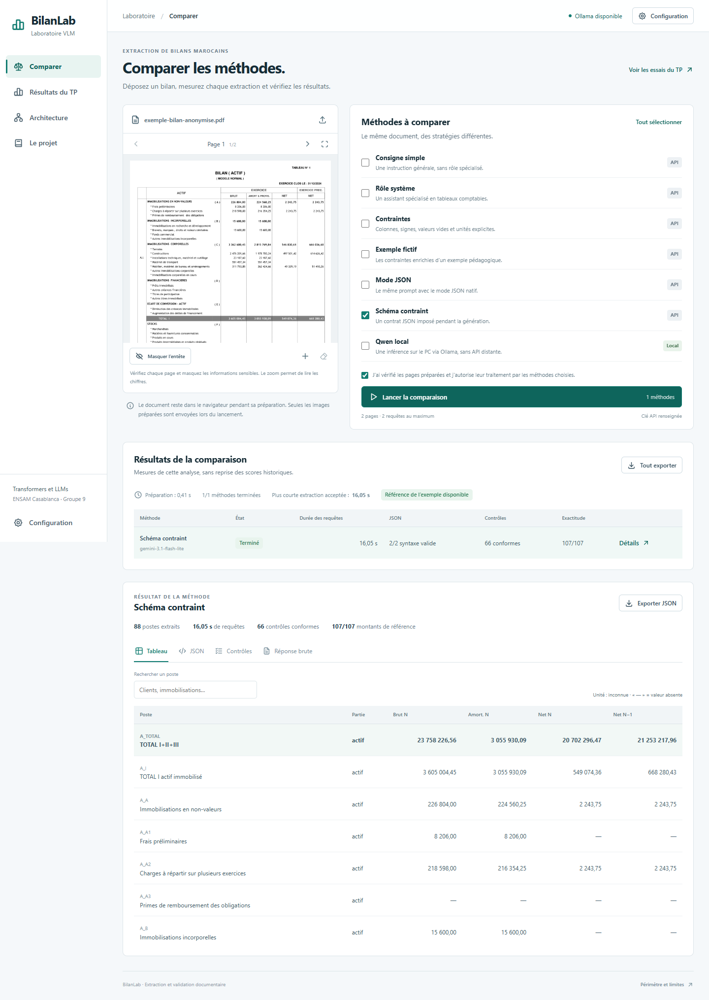

Livrable,Rôle
Notebook technique,"Code complet, fonctions, inférences facultatives et expériences"
Ce notebook de présentation,"Parcours de soutenance autonome, graphiques et toutes les preuves"
Application web,"Importer, masquer, comparer et exporter"
PowerPoint de 21 diapositives,Soutenance visuelle avec notes orales
Dépôt GitHub privé,"Sources, résultats et collaboration autorisée"


In [18]:
panel('<img alt="Capture réelle de BilanLab : comparaison et tableau des postes" src="data:image/png;base64,'+D['app']+'">')
table([
 {'Livrable':'Notebook technique', 'Rôle':'Code complet, fonctions, inférences facultatives et expériences'},
 {'Livrable':'Ce notebook de présentation', 'Rôle':'Parcours de soutenance autonome, graphiques et toutes les preuves'},
 {'Livrable':'Application web', 'Rôle':'Importer, masquer, comparer et exporter'},
 {'Livrable':'PowerPoint de 21 diapositives', 'Rôle':'Soutenance visuelle avec notes orales'},
 {'Livrable':'Dépôt GitHub privé', 'Rôle':'Sources, résultats et collaboration autorisée'}
], 'Comment utiliser les différents livrables')

## 18 — Conclusion et réponses à défendre

Le résultat exploitable vient de la lecture, du contrat explicite et des vérifications. Sur ce bilan, l'API et le nouveau pipeline local hybride sont exacts. L'OCR seul est déjà suffisant ici ; conserver Qwen en relecture n'est utile que si son bénéfice est vérifié sur des cas plus difficiles. La suite prioritaire est un corpus indépendant avec plusieurs mises en page et une double annotation.

In [19]:
table([
 {'Question':'Quels pièges ?', 'Réponse':'Colonnes, cases vides, signes, échelle, masques et hiérarchie.'},
 {'Question':'Quel schéma ?', 'Réponse':'Quatre champs minimaux ; contrat enrichi avec états et provenance.'},
 {'Question':'Quel prompt ?', 'Réponse':'Comparer les 18 essais et les échecs, sans effet universel attribué à une seule technique.'},
 {'Question':'Le JSON garantit-il la vérité ?', 'Réponse':'Il garantit une structure contrôlée ; les chiffres doivent encore être vérifiés.'},
 {'Question':'Sans annotation exhaustive ?', 'Réponse':'Contrôles comptables utiles, mais erreurs compensées possibles.'},
 {'Question':'Pourquoi le local hybride ?', 'Réponse':'OCR léger sur CPU, Qwen ciblé ; le VLM seul initial reste insuffisant.'},
 {'Question':'Comment noter ?', 'Réponse':'107 montants, 74 nets et 352 états/valeurs ; égalité exacte et pages rejetées au dénominateur.'},
 {'Question':'Quelle confidentialité ?', 'Réponse':'Pixels réellement masqués, accès maîtrisés et conditions/API/formalités à vérifier.'}
], 'Les huit réponses essentielles du TP')
table([
 {'Limite':'Un seul bilan réel', 'Conséquence':'Aucune généralisation démontrée'},
 {'Limite':'Référence utilisée au développement, sans double annotation', 'Conséquence':'Ce n’est pas un test indépendant'},
 {'Limite':'Colonnes et catalogue adaptés au modèle fourni', 'Conséquence':'Valider d’autres mises en page'},
 {'Limite':'Qwen déjà chargé lors des nouveaux essais', 'Conséquence':'Temps descriptifs, sans comparaison appariée à froid'},
 {'Limite':'Relecture Qwen assistée par OCR', 'Conséquence':'Pas de seconde annotation indépendante ni gain causal démontré'},
 {'Limite':'Coût local non mesuré', 'Conséquence':'Ne pas affirmer que le local est gratuit'}
], 'Limites qui changent l’interprétation des scores')
details('Environnement de la campagne et matériel enregistré', {'environment':D['environment'],'hardware':D['hardware']})
assert all(r['numeric_correct']==107 and r['controles_ok']==66 and r['erreurs_cellules']==0 for r in D['local']['trials'])
print('Présentation vérifiée : API 107/107 ; local hybride 107/107 sur 3 essais ; données et preuves intégrées.')

Question,Réponse
Quels pièges ?,"Colonnes, cases vides, signes, échelle, masques et hiérarchie."
Quel schéma ?,Quatre champs minimaux ; contrat enrichi avec états et provenance.
Quel prompt ?,"Comparer les 18 essais et les échecs, sans effet universel attribué à une seule technique."
Le JSON garantit-il la vérité ?,Il garantit une structure contrôlée ; les chiffres doivent encore être vérifiés.
Sans annotation exhaustive ?,"Contrôles comptables utiles, mais erreurs compensées possibles."
Pourquoi le local hybride ?,"OCR léger sur CPU, Qwen ciblé ; le VLM seul initial reste insuffisant."
Comment noter ?,"107 montants, 74 nets et 352 états/valeurs ; égalité exacte et pages rejetées au dénominateur."
Quelle confidentialité ?,"Pixels réellement masqués, accès maîtrisés et conditions/API/formalités à vérifier."


Limite,Conséquence
Un seul bilan réel,Aucune généralisation démontrée
"Référence utilisée au développement, sans double annotation",Ce n’est pas un test indépendant
Colonnes et catalogue adaptés au modèle fourni,Valider d’autres mises en page
Qwen déjà chargé lors des nouveaux essais,"Temps descriptifs, sans comparaison appariée à froid"
Relecture Qwen assistée par OCR,Pas de seconde annotation indépendante ni gain causal démontré
Coût local non mesuré,Ne pas affirmer que le local est gratuit


Présentation vérifiée : API 107/107 ; local hybride 107/107 sur 3 essais ; données et preuves intégrées.


### Sources et accès au projet

- Énoncé : `TP5_Extraction_Bilans_VLM.docx` ; données : bilan Groupe 9, deux pages, clôture 2024.
- [Documentation Gemini : sorties structurées](https://ai.google.dev/gemini-api/docs/structured-output) et [tarifs](https://ai.google.dev/gemini-api/docs/pricing).
- [Documentation Ollama](https://docs.ollama.com/capabilities/structured-outputs) et [RapidOCR](https://rapidai.github.io/RapidOCRDocs/main/install_usage/rapidocr/usage/).
- [CNDP : transfert de données à l'étranger](https://www.cndp.ma/transfert-de-donnees-a-letranger/) ; ces éléments ne constituent pas une certification juridique.
- [Dépôt privé BilanLab-VLM](https://github.com/OmarElkhali/BilanLab-VLM), accessible aux collaborateurs autorisés.

**Fin de la présentation — questions et discussion.**